# 03. Hybrid Multi-Agent 구현
**학습 목표:** Research 뒤의 기술·산업 분석을 병렬로 실행하고, 두 결과가 모인 후 보고서를 만든다. 02번의 자료·Agent 설계를 각 셀 안에 재사용해 이 Notebook만으로 실행 가능하다. `.env`의 `OPENAI_API_KEY`로 실제 LLM을 호출하고 `TAVILY_API_KEY`로 실시간 웹 검색을 호출하므로 실행마다 비용이 발생하며, 결과가 실행 시점의 웹 자료에 따라 달라질 수 있다.

## 1. 핵심 개념과 전체 아키텍처
Technology와 Industry는 같은 Research 결과를 읽지만 서로의 출력은 읽지 않는다. 각자 다른 State Key에 쓰므로 Reducer가 필요 없다. `add_edge(["technology_agent", "industry_agent"], "report_writer")`가 두 분기의 완료를 기다린다.

```mermaid
flowchart TD
  S[START] --> R[Research Agent]
  R --> T[Technology Agent]
  R --> I[Industry Agent]
  T --> W[Report Writer]
  I --> W
  W --> V[Review Agent]
  V --> E[END]
```


## 2. Import와 LLM 설정
`common.ai_model.get_llm_model()`은 `.env`의 `OPENAI_API_KEY`로 `ChatOpenAI`를 초기화한다. 모델명은 `.env`의 `LLM_MODEL` 값을 따른다(`.env.example`은 `gpt-4o-mini`). 병렬로 실행되는 `technology_agent`와 `industry_agent`도 이 클라이언트 하나를 공유한다.


In [4]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

from common.ai_model import get_llm_model

llm_model = get_llm_model()

print(llm_model.model_name)

gpt-4o-mini


## 3. Tavily 웹 검색 도구
02번과 같은 방식으로 `TAVILY_API_KEY`를 사용한 실시간 웹 검색을 수행한다. 추가된 산업 분석은 `industry` 범주 검색 결과를 사용한다.

In [1]:
from tavily import TavilyClient

from common.config import TAVILY_API_KEY

tavily_client = TavilyClient(api_key=TAVILY_API_KEY)

# 범주별 검색 질의: Research Agent가 고른 범주를 실제 웹 검색 질의로 변환한다.
CATEGORY_QUERIES = {
    "technology": "2026 AI 기술 동향 성능 벤치마크",
    "industry": "2026 AI 산업 도입 현황 기업 활용률",
    "governance": "AI 위험관리 프레임워크 거버넌스 규제",
}

In [2]:
def search_sources(categories: list[str]) -> list[dict]:
    """Research Agent가 선택한 범주에 대해 Tavily로 실제 웹 검색을 수행한다."""
    cards = []
    for category in categories:
        query = CATEGORY_QUERIES.get(category)
        if not query:
            continue
        response = tavily_client.search(query=query, max_results=2, search_depth="basic")
        for result in response.get("results", []):
            cards.append({
                "id": f"S{len(cards) + 1}",
                "category": category,
                "title": result.get("title", ""),
                "url": result.get("url", ""),
                # 요지는 검색 결과 본문 일부를 그대로 담는다(새로운 수치·사실을 만들지 않는다).
                "evidence": (result.get("content") or "")[:300],
            })
    return cards


def format_sources(cards: list[dict]) -> str:
    """LLM이 출처 ID와 근거를 함께 읽도록 간결하게 정리한다."""
    # 모델이 각 주장에 [S번호]를 그대로 인용할 수 있도록 ID를 맨 앞에 노출한다.
    return "\n".join(
        f'[{card["id"]}] {card["title"]}: {card["evidence"]} ({card["url"]})'
        for card in cards
    )

## 4. 공통 State와 병렬 쓰기
Technology는 `technology_analysis`, Industry는 `industry_analysis`에 쓴다. `research_results`는 읽기 전용 입력이다.


In [6]:
class ReportState(TypedDict, total=False):
        user_request: str
        research_results: list[dict]
        technology_analysis: str
        industry_analysis: str
        final_report: str
        review_notes: str

## 5. Research Agent Subgraph
요청에 `산업`이 포함되면 산업 자료도 검색한다. 이 내부 단계는 상위 Graph의 Fan-out보다 앞서 완료된다.


In [7]:
class ResearchState(TypedDict, total=False):
    user_request: str
    research_scope: list[str]
    research_results: list[dict]


def decide_research_scope(state: ResearchState) -> dict:
    """요청을 보고 자료 조회 범위를 정한다."""
    # 판단 단계: 어떤 카테고리를 조회할지는 요청 내용에 따라 달라진다.
    scope = ["technology", "governance"]
    if "산업" in state["user_request"]:
        scope.append("industry")
    return {"research_scope": scope}


def retrieve_research(state: ResearchState) -> dict:
    """결정된 범위를 도구에 전달해 Tavily 웹 검색 결과를 가져온다."""
    # 실행 단계: 앞서 정한 범위로 웹 검색 도구를 그대로 호출한다(추가 판단 없음).
    return {"research_results": search_sources(state["research_scope"])}


# Research Agent 내부의 판단 → 도구 사용을 별도 Subgraph로 표현한다.
# 이 내부 실행은 상위 Graph의 Fan-out(technology/industry 분기)보다 먼저 끝난다.
research_builder = StateGraph(ResearchState)
research_builder.add_node("decide_scope", decide_research_scope)
research_builder.add_node("web_search", retrieve_research)
research_builder.add_edge(START, "decide_scope")
research_builder.add_edge("decide_scope", "web_search")
research_builder.add_edge("web_search", END)
research_agent = research_builder.compile()

## 6. Research Subgraph 시각화


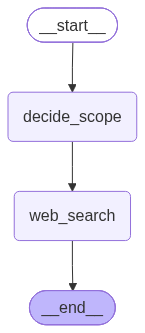

In [8]:
from IPython.display import Image, display

try:
    display(Image(research_agent.get_graph().draw_mermaid_png()))
except Exception as exc:
    # 시각화 서비스가 없어도 Graph의 실행은 계속된다.
    print("PNG 시각화 불가:", type(exc).__name__)
    print(research_agent.get_graph().draw_mermaid())


## 7. 병렬 분석 Agent
두 함수의 입력은 같지만 출력 Key는 다르다. 서로의 분석 결과에 의존하지 않기 때문에 같은 단계에서 실행할 수 있다.


In [9]:
# 두 Agent 모두 같은 research_results를 읽지만 서로 다른 Key에 쓰고 서로의 결과를
# 참조하지 않으므로, Graph에서 같은 Step에 병렬로 실행해도 안전하다.
def technology_agent(state: ReportState) -> dict:
        """제공 자료에서 기술 추세와 평가 한계를 읽는다."""
        prompt = (
            "당신은 AI 기술 분석가다. 기술 자료만 사용해 확인 가능한 추세와 한계를 "
            "2~3문장으로 쓰고 [S번호]로 인용하라.\n"
            f"요청: {state['user_request']}\n자료:\n{format_sources(state['research_results'])}"
        )
        return {"technology_analysis": llm_model.invoke(prompt).content}


def industry_agent(state: ReportState) -> dict:
        """제공 자료에서 조직·의료 분야의 적용과 한계를 읽는다."""
        prompt = (
            "당신은 AI 산업 분석가다. 조직 활용과 의료기기 사례를 구분해 "
            "2~3문장으로 쓰고 [S번호]로 인용하라. 자료 밖의 성과는 만들지 마라.\n"
            f"요청: {state['user_request']}\n자료:\n{format_sources(state['research_results'])}"
        )
        return {"industry_analysis": llm_model.invoke(prompt).content}


## 8. Fan-in 이후 작성·검토
Writer는 두 분석 Key를 모두 읽는다. 둘 중 하나라도 없다면 바로 오류가 나므로 잘못된 Edge 구성을 발견할 수 있다.


In [10]:
def report_writer(state: ReportState) -> dict:
        """기술·산업 분석을 한 보고서로 통합한다."""
        # Fan-in 지점: technology_analysis와 industry_analysis가 둘 다 채워진 뒤에만 실행된다.
        # 둘 중 하나라도 없으면 KeyError가 나므로 Edge 구성 실수를 바로 알아챌 수 있다.
        prompt = (
            "당신은 보고서 작성자다. 기술, 산업, 한계, 참고자료 절을 가진 짧은 "
            "Markdown 보고서를 작성하라. 모든 확인 가능한 주장에 [S번호]를 붙이고 "
            "자료 밖의 수치·사례를 쓰지 마라.\n"
            f"기술 분석: {state['technology_analysis']}\n"
            f"산업 분석: {state['industry_analysis']}\n"
            f"자료:\n{format_sources(state['research_results'])}"
        )
        return {"final_report": llm_model.invoke(prompt).content}


## 9. Review Agent의 자료 대조
검토 Agent는 인용 ID의 존재를 코드로 검사하고, 제공된 카드와 주장 사이의 차이를 모델에 묻는다. 이 의견만으로 원문 검증이 완료되지는 않는다.


In [11]:
import re


def review_agent(state: ReportState) -> dict:
    """인용 ID를 기계적으로 검사하고 주장·근거 대조 의견을 구한다."""
    # 1) 코드로 하는 기계적 검사: 보고서의 [S번호]가 실제 자료 카드에 존재하는지만 확인한다.
    known_ids = {card["id"] for card in state["research_results"]}
    cited_ids = set(re.findall(r"\[(S\d+)\]", state["final_report"]))
    unknown_ids = cited_ids - known_ids
    citation_check = (
        f"인용 ID {len(cited_ids)}개, 미등록 ID: {sorted(unknown_ids)}"
        if cited_ids else "인용 ID 없음: 출처 표기가 필요하다."
    )
    # 2) LLM이 하는 의미 판단: 주장이 자료 내용과 실제로 들어맞는지는 모델에 맡긴다.
    prompt = (
        "당신은 보고서 검토자다. 자료 카드와 보고서 주장을 비교해 "
        "'근거로 설명 가능', '자료로 판단 불가', '추가 확인 필요'로 구분하라. "
        "카드에 없는 수치·인과관계·일반화는 지적하라.\n"
        f"자료:\n{format_sources(state['research_results'])}\n"
        f"보고서:\n{state['final_report']}"
    )
    judgment = llm_model.invoke(prompt).content
    return {"review_notes": (
        f"{citation_check}\n\n{judgment}\n\n"
        "주의: 인용 ID 검사는 출처 존재만 확인한다. 주장과 원문의 일치는 사람이 최종 대조해야 한다."
    )}


## 10. Graph 구성과 Compile
Research에서 두 Agent로 **Fan-out**하고, 리스트 선행 Node Edge로 **Fan-in**한다. 병렬 Agent가 같은 Key를 동시에 업데이트하지 않으므로 Reducer가 없다.


In [12]:
builder = StateGraph(ReportState)
builder.add_node("research_agent", research_agent)
builder.add_node("technology_agent", technology_agent)
builder.add_node("industry_agent", industry_agent)
builder.add_node("report_writer", report_writer)
builder.add_node("review_agent", review_agent)

builder.add_edge(START, "research_agent")
# Fan-out: 같은 research_agent에서 두 Edge가 나가므로, 다음 Step에서
# technology_agent와 industry_agent가 함께(병렬로) 실행 대상이 된다.
builder.add_edge("research_agent", "technology_agent")
builder.add_edge("research_agent", "industry_agent")
# Fan-in: 리스트로 선행 Node 둘을 지정하면 둘 다 완료된 뒤에만 report_writer가 실행된다.
builder.add_edge(["technology_agent", "industry_agent"], "report_writer")
builder.add_edge("report_writer", "review_agent")
builder.add_edge("review_agent", END)
graph = builder.compile()


## 11. Graph 시각화


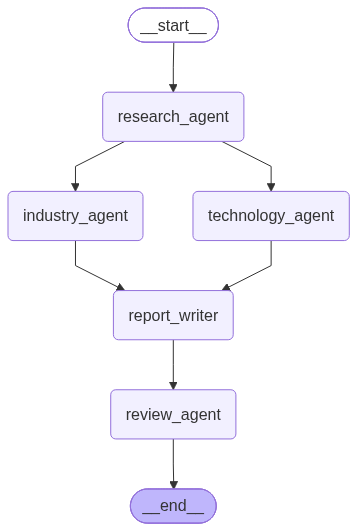

In [13]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    # 시각화 서비스가 없어도 Graph의 실행은 계속된다.
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())


## 12. 실행과 병렬 결과 통합 확인
`stream_mode="updates"`에서 두 분석의 출력 순서는 환경에 따라 달라질 수 있다. 두 Key가 모두 채워진 뒤 Writer가 실행되는지만 확인한다. 매 실행마다 네 Agent가 모두 LLM을 호출하므로 API 비용이 발생한다.


In [14]:
initial_state = {"user_request": "AI 기술과 산업별 활용 동향을 분석한 보고서를 작성하라."}
final_state = dict(initial_state)
completed = []

# technology_agent/industry_agent는 같은 Step에서 병렬 실행되므로 둘 사이의 완료 순서는
# 보장되지 않는다. completed 목록으로 실제 실행 순서를 기록해 두면, 순서 자체가 아니라
# "report_writer가 둘 다 끝난 뒤에 실행됐는지"라는 Fan-in 불변식만 검증할 수 있다.
for update in graph.stream(initial_state, stream_mode="updates"):
    for node_name, changed_values in update.items():
        completed.append(node_name)
        final_state.update(changed_values)
        print(f"{node_name}: {list(changed_values)}")

# 검증: report_writer가 technology_agent와 industry_agent 둘 다 끝난 뒤에 실행됐는지 확인한다.
assert completed.index("report_writer") > completed.index("technology_agent")
assert completed.index("report_writer") > completed.index("industry_agent")
assert final_state["technology_analysis"] and final_state["industry_analysis"]
assert final_state["final_report"] and final_state["review_notes"]


research_agent: ['user_request', 'research_results']
industry_agent: ['industry_analysis']
technology_agent: ['technology_analysis']
report_writer: ['final_report']
review_agent: ['review_notes']


## 13. 결과 확인


In [16]:
from IPython.display import Markdown, display

display(Markdown(final_state["final_report"]))
display(Markdown("### 검토 의견\n" + final_state["review_notes"]))
print("참고자료:")
for card in final_state["research_results"]:
    print(f"[{card['id']}] {card['title']} — {card['url']}")


# AI 기술 활용 동향 보고서

## 기술 분석
AI 기술의 활용 동향은 다양한 산업에서 급속히 확산되고 있으며, 특히 생성형 AI의 도입이 두드러지고 있다. 2026년까지 국내 기업의 85%가 생성형 AI를 도입할 것으로 예상되며, IT 및 통신 분야에서 가장 높은 활용률을 보일 것으로 나타났다[S5]. 그러나 AI의 도입에 따른 위험 관리와 윤리적 고려가 여전히 부족한 상황이며, 많은 기업들이 이러한 프레임워크를 구축하는 데 어려움을 겪고 있다[S3][S4]. 

AI 기술의 성능 평가를 위한 벤치마크의 필요성도 커지고 있으며, 이는 AI 모델 간의 공정한 비교를 위한 중요한 요소로 부각되고 있다[S1].

## 산업 분석
AI 기술은 다양한 산업에서 활용되고 있으며, 특히 조직 내에서는 효율성 및 생산성 개선을 통해 의사결정과 데이터 기반 인사이트를 강화하는 데 기여하고 있다. 2026년에는 기업의 85%가 생성형 AI를 도입할 것으로 예상되며, 이는 IT 및 통신/방송 분야에서 가장 높은 도입률을 보일 것으로 나타났다[S5]. 반면, 의료기기 분야에서는 AI가 진단 및 치료 지원 시스템에 적용되어 환자의 건강 상태를 모니터링하고 맞춤형 치료를 제공하는 데 중요한 역할을 하고 있다[S6].

## 한계
AI 기술의 도입과 활용이 증가하고 있지만, 여전히 많은 기업들이 AI의 위험 관리 및 윤리적 고려에 대한 체계적인 접근이 부족하다. 이러한 한계는 AI 기술의 신뢰성과 안전성을 저해할 수 있으며, 기업들이 AI를 효과적으로 활용하는 데 장애가 될 수 있다[S3][S4].

## 참고자료
- [S1] 한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및...
- [S3] AI 위험 관리 프레임워크: 거버넌스, 리스크, 규정 준수 | 인사이트리포트 | 삼성SDS
- [S4] AI 규제 프레임워크 | FlowHunt
- [S5] “2026년 국내 기업 85%가 생성형 AI 도입…10곳

### 검토 의견
인용 ID 5개, 미등록 ID: []

보고서의 주장과 자료 카드를 비교하여 다음과 같이 구분하였습니다.

1. **근거로 설명 가능**
   - "2026년까지 국내 기업의 85%가 생성형 AI를 도입할 것으로 예상되며, IT 및 통신 분야에서 가장 높은 활용률을 보일 것으로 나타났다." [S5]
   - "AI 기술의 성능 평가를 위한 벤치마크의 필요성도 커지고 있으며, 이는 AI 모델 간의 공정한 비교를 위한 중요한 요소로 부각되고 있다." [S1]

2. **자료로 판단 불가**
   - "AI의 도입에 따른 위험 관리와 윤리적 고려가 여전히 부족한 상황이며, 많은 기업들이 이러한 프레임워크를 구축하는 데 어려움을 겪고 있다." [S3][S4]
   - "AI 기술의 도입과 활용이 증가하고 있지만, 여전히 많은 기업들이 AI의 위험 관리 및 윤리적 고려에 대한 체계적인 접근이 부족하다." [S3][S4]

3. **추가 확인 필요**
   - "AI 기술은 다양한 산업에서 활용되고 있으며, 특히 조직 내에서는 효율성 및 생산성 개선을 통해 의사결정과 데이터 기반 인사이트를 강화하는 데 기여하고 있다." [S6]
   - "의료기기 분야에서는 AI가 진단 및 치료 지원 시스템에 적용되어 환자의 건강 상태를 모니터링하고 맞춤형 치료를 제공하는 데 중요한 역할을 하고 있다." [S6]

### 지적 사항
- 보고서에서 언급된 "AI의 도입에 따른 위험 관리와 윤리적 고려가 여전히 부족한 상황"에 대한 구체적인 수치나 사례가 부족하여 판단하기 어렵습니다.
- "AI 기술의 도입과 활용이 증가하고 있지만"이라는 주장은 구체적인 수치나 데이터 없이 일반화된 주장으로 보입니다. 추가적인 자료가 필요합니다.
- "의사결정과 데이터 기반 인사이트를 강화하는 데 기여하고 있다"는 주장은 구체적인 사례나 수치가 없어 일반화된 주장으로 판단됩니다.

주의: 인용 ID 검사는 출처 존재만 확인한다. 주장과 원문의 일치는 사람이 최종 대조해야 한다.

참고자료:
[S1] 한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및... — https://www.facebook.com/ITKOREANIA/posts/-the-ai-report-2026-1-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B-%ED%98%84%ED%99%A9-%EB%B6%84%EC%84%9D-%EB%B0%8F-%EC%A0%95%EB%B6%80-%EC%A3%BC%EB%8F%84%EC%9D%98-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%A7%88%EB%A0%A8-%ED%95%84%EC%9A%94%EC%84%B1-ai-%EC%84%B1%EB%8A%A5-%EB%AC%B4%EC%97%87%EC%9C%BC%EB%A1%9C-%EC%96%B4%EB%96%BB%EA%B2%8C-%ED%8F%89%EA%B0%80%ED%95%B4%EC%95%BC-%ED%95%A0/1224540443199953
[S2] 인공지능 벤치마크 - 나무위키 — https://namu.wiki/w/%EC%9D%B8%EA%B3%B5%EC%A7%80%EB%8A%A5%20%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC
[S3] AI 위험 관리 프레임워크: 거버넌스, 리스크, 규정 준수 | 인사이트리포트 | 삼성SDS — https://www.samsungsds.com/kr/insights/ai-risk-management-framework.html
[S4] AI 규제 프레임워크 | FlowHunt — https://www.flowhunt.io/ko/%EC%9A%A9%EC%96%B4%EC%A7%91/ai-regulatory-frameworks
[S5] “2026년 국내 기업 85%가 생성형 AI 도입…10곳 중 8곳 예산 확대” — https://www.cio.com/article/4045735/2026%EB%85%

## 결과를 markdown 파일로 저장

In [ ]:
import os

def build_full_markdown(state: dict) -> str:
    """최종 보고서, 검토 의견, 출처를 하나의 Markdown 문서로 합친다."""
    sources = "\n".join(
        f"- [{card['id']}] [{card['title']}]({card['url']})"
        for card in state["research_results"]
    )
    return (
        f"{state['final_report']}\n\n"
        f"## 검토 의견\n\n{state['review_notes']}\n\n"
        f"## 참고자료\n\n{sources}\n"
    )


os.makedirs("output_docs", exist_ok=True)
markdown_path = "output_docs/하이브리드_분석_결과.md"
with open(markdown_path, "w", encoding="utf-8") as f:
    f.write(build_full_markdown(final_state))

print(f"저장 완료: {markdown_path}")


저장 완료: output_docs/하이브리드_분석_결과.md


## 14. Reducer 사용 조건과 Sequential 비교
같은 Step에서 여러 Node가 **동일 Key**에 값을 누적하면 `Annotated[list[str], operator.add]` 같은 Reducer가 필요하다. 이 Graph는 서로 다른 Key를 쓰므로 Reducer를 넣지 않는다.

| 구조 | 분석 간 의존 | 장점 | 주의점 |
|---|---|---|---|
| Sequential | 뒤 Agent가 앞 결과를 읽을 수 있음 | 흐름이 단순함 | 독립 업무도 기다림 |
| Hybrid | 두 분석이 서로 독립 | 대기 시간을 줄일 여지가 있음 | API 제한·비용·Fan-in 확인 필요 |

병렬이 항상 더 빠르지는 않다. 실제 속도는 모델 호출 지연, API 동시성 제한, 실행 환경에 좌우된다.


## 15. 수강생 미션
**AI Security & Governance Analyst**를 세 번째 병렬 분기로 추가한다. `security_analysis` Key를 State에 추가하고 Research 자료의 S4를 사용한다. Writer가 기술·산업·보안 세 결과를 모두 받은 뒤 실행되도록 Fan-in Edge를 수정한다. 동일 Key를 여러 Agent가 쓰지 않는다면 Reducer를 추가하지 않는다.
